# Lab 11 — Attention with RNN


# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [5]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [6]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [8]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [9]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

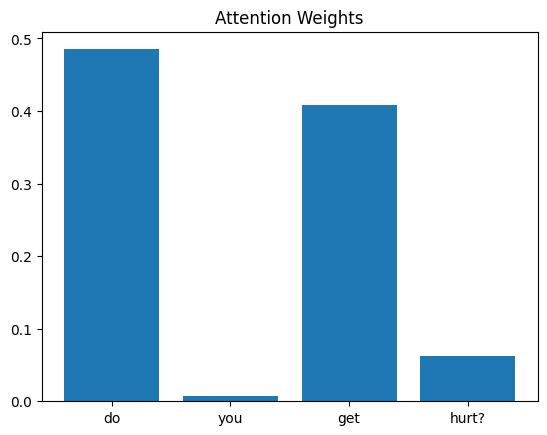

In [10]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

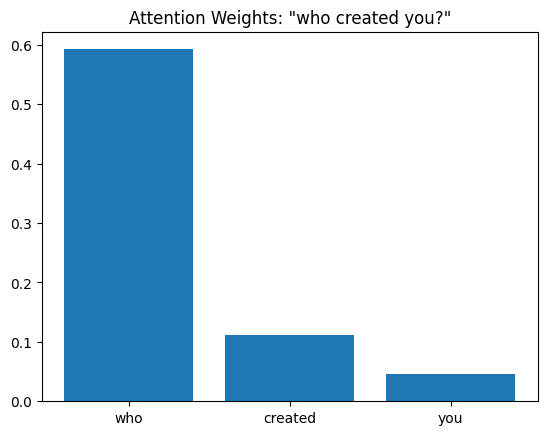

Highest attention: 'who' (0.592)   |   predicted answer_id: 3   (true: 3)



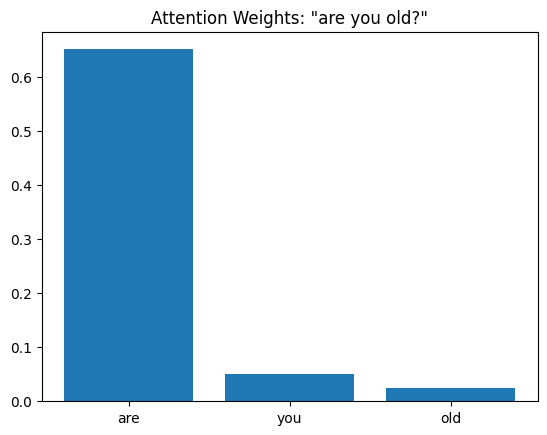

Highest attention: 'are' (0.652)   |   predicted answer_id: 3   (true: 1)



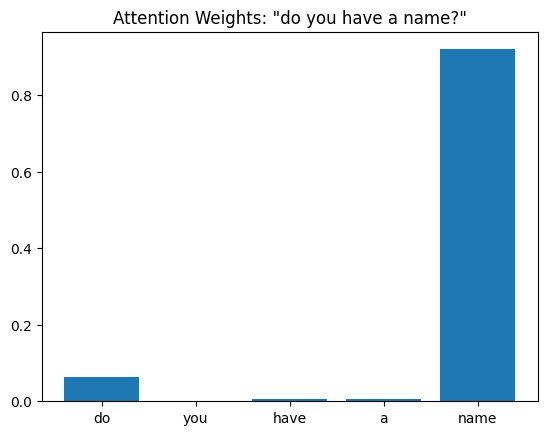

Highest attention: 'name' (0.920)   |   predicted answer_id: 2   (true: 8)



In [11]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

def show_attention(question):
    idx = df.index[df["question"] == question][0]          # row of this question in the dataset
    words = text_to_word_sequence(question)                # same words the tokenizer used
    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])
    w = weights[0, :len(words)].tolist()

    plt.bar(words, w)
    plt.title(f'Attention Weights: "{question}"')
    plt.show()

    top = words[w.index(max(w))]
    print(f"Highest attention: '{top}' ({max(w):.3f})   |   predicted answer_id: {prediction.argmax(1).item()}   (true: {y[idx].item()})")
    print()

# three questions from different answer groups
for q in ["who created you?", "are you old?", "do you have a name?"]:
    show_attention(q)

**Answer:**

Only sometimes. For "who created you?" the model looks mostly at 'who' (0.59), the question word, and it predicts the right answer group (3). For "do you have a name?" it gives 'name' a very high weight (0.92), which is exactly the key word, but it still predicts the wrong answer group (2 instead of 8). For "are you old?" the highest weight goes to 'are' (0.65), a generic word, and it also predicts the wrong group (3 instead of 1), when the important word is 'old'. So the highest-attention word is sometimes the important one, but not always. The model is very small and trained for only 50 steps, so its attention weights are not very reliable explanations.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

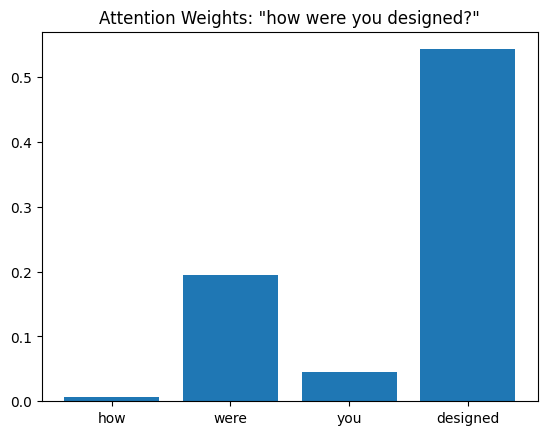

Highest attention: 'designed' (0.543)   |   predicted answer_id: 11   (true: 3)



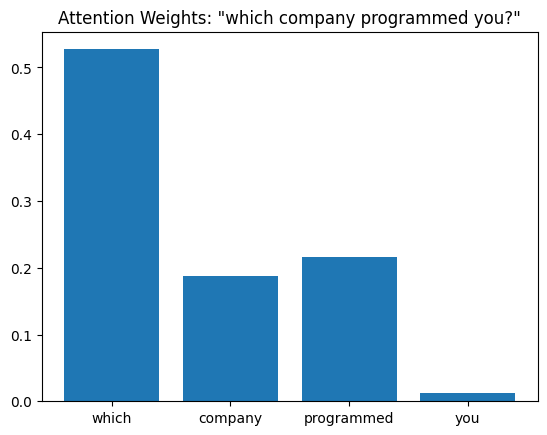

Highest attention: 'which' (0.527)   |   predicted answer_id: 3   (true: 3)



In [12]:
# two questions with the same meaning (both ask who made the bot) but different wording
pair = ["how were you designed?", "which company programmed you?"]

for q in pair:
    show_attention(q)

**Answer:**

The two questions mean the same thing (both ask who made the bot), but the model focuses on different words: 'designed' (0.54) in "how were you designed?" and 'which' (0.53) in "which company programmed you?". They share no important word except "you", so there is nothing common for the attention to land on. This suggests that attention does not understand meaning. It only learns, from the training data, how much weight each particular word deserves, so a paraphrase with different words gets a different attention pattern. The model also predicted the right answer (id 3) for the second question but not for the first, which shows the attention is only as good as the training. Attention tells us which words the model used for its decision, not whether the model understood the question.
